# Modelado experimental 

## Criterios de evaluación y selección de modelos



En este proyecto se asumirá una distribución de clases del 70 % para la clase positiva (suscripción) y del 30 % para la clase negativa (no suscripción). Asimismo, se considerará que el costo asociado a un falso negativo (FN), es decir, no identificar a un cliente que se suscribiría, es superior al de un falso positivo (FP), que consiste en predecir una suscripción cuando esta no se produce.

Bajo este supuesto, se priorizará Recall como métrica principal de evaluación, con el objetivo de maximizar la proporción de suscripciones potenciales correctamente identificadas y reducir la cantidad de falsos negativos.

Como métrica complementaria, se utilizará PR-AUC (área bajo la curva Precision-Recall), que permitirá evaluar la relación entre Precision y Recall a distintos umbrales de clasificación, considerando el impacto de los falsos positivos sobre la calidad de las predicciones positivas.

Finalmente, desde una perspectiva de negocio, se analizará el costo esperado para distintos umbrales de clasificación, con el objetivo de identificar el punto de operación que minimice el costo asociado a los errores. Este análisis permitirá comparar los modelos no solo por su capacidad predictiva, sino también por su adecuación a los costos del problema.

En consecuencia, la selección del modelo considerará tres dimensiones complementarias: la capacidad de detectar suscripciones potenciales (Recall), el equilibrio entre Precision y Recall a distintos umbrales (PR-AUC) y el impacto económico de los errores (costo esperado).

## Librerías

In [87]:
import os
import sys

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [88]:
import pprint

In [89]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd
import scipy.stats as stats

In [90]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import graphviz
from IPython.display import Image

In [91]:
# ============================================================
# 3. PREPROCESAMIENTO Y REDUCCIÓN DE DIMENSIONALIDAD
# ============================================================

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import trustworthiness

from sklearn.feature_selection import SelectKBest, f_classif, chi2
from scipy.stats import chi2_contingency

In [92]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================

from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

from xgboost import XGBClassifier

In [93]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)

from sklearn.pipeline import Pipeline

from src.experiment_factory import ExperimentFactory
from src.model_optimizer import ModelOptimizer
from src.experiment_evaluator import ExperimentEvaluator
from src.experiment_tracker import ExperimentTracker

In [94]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor

In [95]:
import joblib

### Importacion de datos

In [96]:
path_df_processed = '../data/3_gold/df_processed.csv'
df_processed = pd.read_csv(path_df_processed)
df_processed.sample(5)

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
3053,32,Female,Shoes,Footwear,91,Maine,L,Brown,Winter,3.2,No,Next Day Air,No,22,Bank Transfer,Monthly
3587,33,Female,Sweater,Clothing,90,Virginia,S,Violet,Summer,4.4,No,Standard,No,33,Debit Card,Annually
3230,49,Female,Sneakers,Footwear,49,Kansas,M,Olive,Summer,2.5,No,Next Day Air,No,38,Debit Card,Annually
2103,30,Male,Pants,Clothing,86,Indiana,S,Red,Summer,3.7,No,Store Pickup,No,21,Venmo,Weekly
2945,32,Female,Belt,Accessories,49,Delaware,M,Charcoal,Summer,4.8,No,Free Shipping,No,1,Credit Card,Every 3 Months


### Separacion de datos

In [97]:
top_columns = joblib.load('../artifacts/top_columns.joblib')

In [98]:
top_columns

['purchase_amount_usd',
 'review_rating',
 'previous_purchases',
 'promo_code_used',
 'gender',
 'location',
 'shipping_type',
 'payment_method',
 'frequency_of_purchases']

In [99]:
g_preprocessor = GeneralPreprocessor()

In [100]:
df_processed = g_preprocessor.fit_transform(X=df_processed)
df_processed = pd.DataFrame(data=df_processed, columns=g_preprocessor.get_feature_names_out())
df_processed

,age,gender,item_purchased,category_item,purchase_amount_usd,location,size,color,season,review_rating,subscription_status,shipping_type,promo_code_used,previous_purchases,payment_method,frequency_of_purchases
0,55,male,blouse,clothing,53,kentucky,l,gray,winter,3.1,yes,express,yes,14,venmo,bi-weekly
1,19,male,sweater,clothing,64,maine,l,maroon,winter,3.1,yes,express,yes,2,cash,bi-weekly
2,50,male,jeans,clothing,73,massachusetts,s,maroon,spring,3.1,yes,free shipping,yes,23,credit card,weekly
3,21,male,sandals,footwear,90,rhode island,m,maroon,spring,3.5,yes,next day air,yes,49,paypal,weekly
4,45,male,blouse,clothing,49,oregon,m,turquoise,spring,2.7,yes,free shipping,yes,31,paypal,annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,40,female,hoodie,clothing,28,virginia,l,turquoise,summer,4.2,no,2-day shipping,no,32,venmo,weekly
3896,52,female,backpack,accessories,49,iowa,l,white,spring,4.5,no,store pickup,no,41,bank transfer,bi-weekly
3897,46,female,belt,accessories,33,new jersey,l,green,spring,2.9,no,standard,no,24,venmo,quarterly
3898,44,female,shoes,footwear,77,minnesota,s,brown,summer,3.8,no,express,no,24,venmo,weekly


In [101]:
# separo las las variables de la variable target
X = df_processed[top_columns].copy()
y = df_processed['subscription_status'].copy()

In [102]:
y = y.map({'no':0, 'yes':1})

In [103]:
# Divido las variable target y el resto de variables en testeo y prueba utilizando un 35% de datos para prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### Instancia y creación de grilla de hiperparámeotros por medio de GridSearchCV

No se observo relaciones o tendencias lineales de manera bivariada. Pero antes de descartar una posible relacion lineal mas alla de combinaciones bivaraiadas, y dada la muestra relativamente chica. Dado el ruido y en general baja seńal observada en el analisis bivariado contra larget, provaremos multiples combinaciones de reducciones lineales y no lineales, al igual que modelos de clasificación robustos y con cierta regularización o robustes ante la varianza en las predicciones.

#### Estrategias de reducción de dimensionalidad

LDA

In [104]:
LDA = LinearDiscriminantAnalysis(n_components=1)

In [105]:
LDA_grid = {'n_components': [1]}

Combinaciones de Estrategias de reducción y grilla de hiperparámetros:

In [106]:
reductions = {
    "options": {
        "Sin reducción": "passthrough",
        "LDA": LDA,
    },

    "grids": {
        "Sin reducción": {},
        "LDA": LDA_grid,
    },

}

#### Modelos base

ElasticNet

In [107]:
elasticnet = LogisticRegression(
    solver="saga",
    penalty="elasticnet",
    max_iter=3000,
    random_state=42
)

grid_elasticnet = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}

Arbol individual (con inyección de coste hipotetico de 0.4 para no subscritos y 0.6 para predecir subscriptos.)

In [108]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    class_weight={0:0.4, 1:0.6}
)

grid_decision_tree = {
    # Control de profundidad
    "max_depth": [3, 5, 7, 9],
    # Fracción mínima de muestras para dividir un nodo
    "min_samples_split": [0.007, 0.01, 0.02, 0.05, 0.10],
    # Fracción mínima de muestras por hoja
    "min_samples_leaf": [0.01, 0.02, 0.05, 0.10],
    # Poda del árbol
    "ccp_alpha": [0.0, 0.001, 0.01],
    # Reducción mínima de impureza para dividir
    "min_impurity_decrease": [0.0005, 0.001, 0.005, 0.01, 0.015],
    # Criterios de división
    "criterion": ["gini", "entropy", "log_loss"]
}

#### Modelos avanzados: Ensamblado y redes neuronales

Random Forest

In [109]:
random_forest = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

grid_random_forest = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 7],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5]
}

XGBoost

In [110]:
xgboost = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    n_jobs=1
)

grid_xgboost = {
    "n_estimators": [200, 500],
    "max_depth": [3, 6, 10],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8, 1.0]
}

MLPClassifier

In [111]:
mlp = MLPClassifier(
    max_iter=500,
    early_stopping=True,
    random_state=42
)

grid_mlp = {
    "hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01]
}

Combinaciones de modelos y grilla de hiperparámetros:

In [112]:
models = {
    "options": {
        "ElasticNet": elasticnet,
        "DTC":decision_tree,
        'RFC': random_forest,
        'XGBC':xgboost,
        'MLP':mlp
    },

    "grids": {
        "ElasticNet": grid_elasticnet,
        "DTC":grid_decision_tree,
        'RFC': grid_random_forest,
        'XGBC':grid_xgboost,
        'MLP':grid_mlp
    },
}

Cargando artefactos:

In [113]:
preprocessor = joblib.load('../artifacts/preprocessor.joblib')

Pipeline:

In [114]:
pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("reduction", "passthrough"),
    ("model", clone(elasticnet))
])

Combinaciones de experimentos: Estrategias de reducción x (estrategias de modelado x hiperparámtros)

In [115]:
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()

for experiment in experiments:
    print(f"Modelo: {experiment['nombre_modelo']}")
    print(f"Reducción: {experiment['reduccion']}")
    print(f"Grid: {experiment['param_grid']}")
    print("-" * 60)

Modelo: ElasticNet
Reducción: Sin reducción
Grid: {'model__C': [0.001, 0.01, 0.1, 1, 10, 100], 'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9], 'reduction': ['passthrough'], 'model': [LogisticRegression(max_iter=3000, penalty='elasticnet', random_state=42,
                   solver='saga')]}
------------------------------------------------------------
Modelo: ElasticNet
Reducción: LDA
Grid: {'model__C': [0.001, 0.01, 0.1, 1, 10, 100], 'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9], 'reduction': [LinearDiscriminantAnalysis(n_components=1)], 'reduction__n_components': [1], 'model': [LogisticRegression(max_iter=3000, penalty='elasticnet', random_state=42,
                   solver='saga')]}
------------------------------------------------------------
Modelo: DTC
Reducción: Sin reducción
Grid: {'model__max_depth': [3, 5, 7, 9], 'model__min_samples_split': [0.007, 0.01, 0.02, 0.05, 0.1], 'model__min_samples_leaf': [0.01, 0.02, 0.05, 0.1], 'model__ccp_alpha': [0.0, 0.001, 0.01], 'model__min_impur

### Entrenamiento y optimización con GridSearchCV

In [116]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

optimizer = ModelOptimizer(
    pipeline=pipeline,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=0
)

optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train
)

/opt/anaconda3/envs/data_science/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/data_science/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/data_science/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/data_science/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (v

In [117]:
evaluator = ExperimentEvaluator(
    task="classification",
    metrics=[
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "average_precision",
        "log_loss"
    ],
    average="weighted"
)

tracker = ExperimentTracker()

for key, search in optimizer.search_objects.items():

    model_name, reduction_name = key

    result = evaluator.evaluate(
        grid_search=search,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        model_name=model_name,
        reduction_name=reduction_name
    )

    tracker.log_result(result)
df_experiments = tracker.get_results()

df_experiments = tracker.sort_by(
    metric="CV score",
    ascending=False
)

display(df_experiments)

,Modelo,Reducción,Mejores parámetros,CV score,CV train score,CV score std,CV train-validation gap,Train accuracy,Train balanced_accuracy,Train precision,...,Test average_precision,Test log_loss,Train-Test gap recall,Train-Test gap balanced_accuracy,Train-Test gap f1,Train-Test gap roc_auc,Train-Test gap average_precision,Train-Test gap log_loss,Train-Test gap precision,Train-Test gap accuracy
0,DTC,Sin reducción,{'model': DecisionTreeClassifier(class_weight=...,0.896592,0.911719,0.014487,0.015127,0.843077,0.893503,0.901684,...,0.639017,0.309821,0.012308,0.012723,0.013326,0.023110,0.025510,-0.027874,0.008586,0.012308
1,RFC,LDA,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.895760,0.984237,0.016253,0.088477,0.877265,0.916705,0.916292,...,0.631656,0.312642,0.062906,0.082990,0.061736,0.105590,0.338182,-0.084040,0.065717,0.062906
2,MLP,Sin reducción,"{'model': MLPClassifier(early_stopping=True, m...",0.895757,0.895864,0.007383,0.000107,0.840000,0.878895,0.889468,...,0.621644,0.369954,0.015385,0.012893,0.016047,0.023483,0.020817,-0.025749,0.010263,0.015385
3,XGBC,Sin reducción,"{'model': XGBClassifier(base_score=None, boost...",0.895655,0.931929,0.015982,0.036274,0.852650,0.887480,0.895093,...,0.684039,0.300487,0.021880,0.020275,0.022008,0.033610,0.065511,-0.033957,0.016325,0.021880
4,DTC,LDA,{'model': DecisionTreeClassifier(class_weight=...,0.894908,0.921925,0.016310,0.027018,0.843419,0.893735,0.901818,...,0.641534,0.312421,0.012650,0.012955,0.013641,0.020657,0.029569,-0.031986,0.008720,0.012650
5,RFC,Sin reducción,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.893555,0.962472,0.015703,0.068917,0.858462,0.900188,0.904794,...,0.696220,0.305331,0.026667,0.024951,0.026554,0.061507,0.175605,-0.044871,0.018106,0.026667
6,XGBC,LDA,"{'model': XGBClassifier(base_score=None, boost...",0.893202,0.921559,0.015026,0.028357,0.843761,0.893133,0.901197,...,0.656744,0.300729,0.010940,0.010907,0.011990,0.027047,0.062566,-0.028207,0.007277,0.010940
7,ElasticNet,Sin reducción,"{'model': LogisticRegression(max_iter=3000, pe...",0.889469,0.893425,0.012465,0.003956,0.833846,0.866372,0.879889,...,0.627064,0.326662,0.019487,0.018038,0.019982,0.018043,-0.000871,-0.026207,0.015866,0.019487
8,ElasticNet,LDA,"{'model': LogisticRegression(max_iter=3000, pe...",0.884340,0.899752,0.011256,0.015411,0.736752,0.500000,0.542804,...,0.615147,0.409951,0.027009,0.000000,0.035826,0.023701,0.029405,-0.023663,0.039068,0.027009
9,MLP,LDA,"{'model': MLPClassifier(early_stopping=True, m...",0.884340,0.899752,0.011256,0.015411,0.843077,0.893503,0.901684,...,0.615147,0.627779,0.012308,0.012723,0.013326,0.023701,0.029405,-0.002726,0.008586,0.012308


#### Arbol de desición simple

In [123]:
optimizer.search_objects['DTC', 'Sin reducción']

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('all_columns',
                                                         GeneralPreprocessor()),
                                                        ('by_data_type_columns',
                                                         ColumnTransformer(sparse_threshold=0,
                                                                           transformers=[('numeric',
                                                                                          'passthrough',
                                                                                          ['purchase_amount_usd',
                                                                                           'review_rating',
                                                                                           'previous_purchases'])...
                                                          random_state=42)],
                         'model__ccp_alpha': [0.0, 0.001, 0.01],
                         'model__criterion': ['gini', 'entropy', 'log_loss'],
                         'model__max_depth': [3, 5, 7, 9],
                         'model__min_impurity_decrease': [0.0005, 0.001, 0.005,
                                                          0.01, 0.015],
                         'model__min_samples_leaf': [0.01, 0.02, 0.05, 0.1],
                         'model__min_samples_split': [0.007, 0.01, 0.02, 0.05,
                                                      0.1],
                         'reduction': ['passthrough']},
             return_train_score=True, scoring='roc_auc')

In [136]:
pipeline_decision_tree_sin_reduccion = optimizer.search_objects['DTC', 'Sin reducción'].best_estimator_

In [137]:
decision_tree_sin_reduccion = pipeline_decision_tree_sin_reduccion.named_steps['model']

In [138]:
decision_tree_sin_reduccion.get_params

<bound method BaseEstimator.get_params of DecisionTreeClassifier(class_weight={0: 0.4, 1: 0.6}, criterion='entropy',
                       max_depth=5, min_impurity_decrease=0.0005,
                       min_samples_leaf=0.02, min_samples_split=0.007,
                       random_state=42)>

##### Evaluación individual 

In [139]:
X_test = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test)

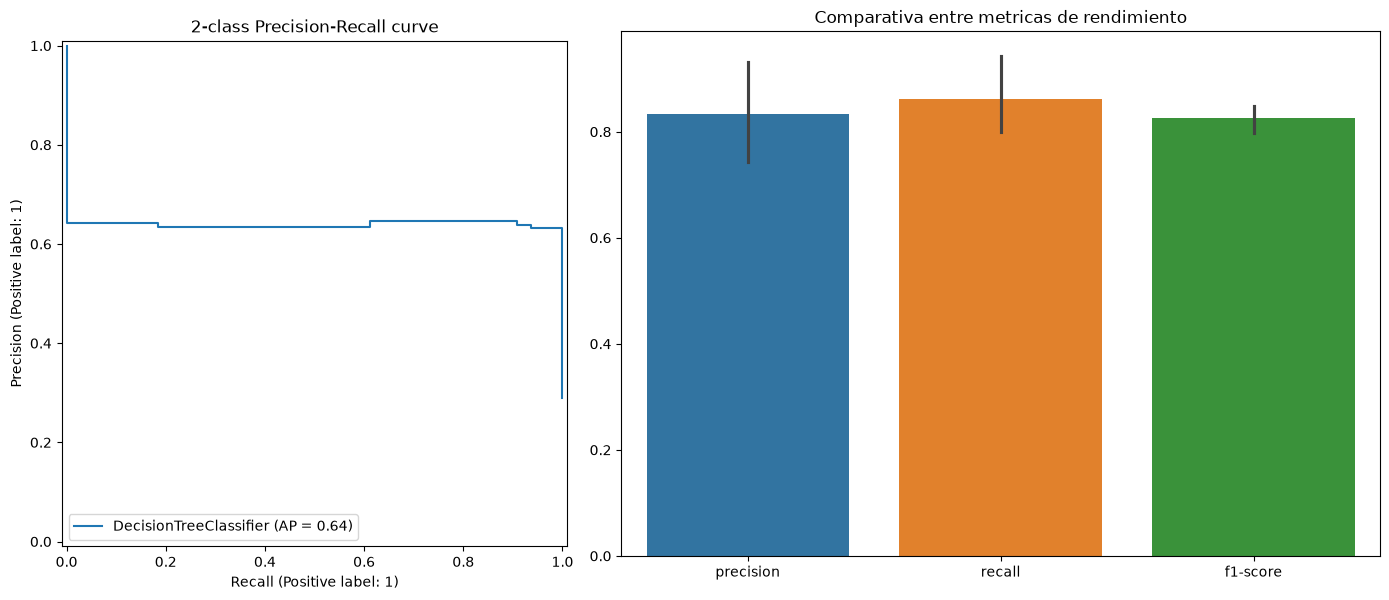

{'y_pred': array([1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
        0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 0,

In [140]:
eval_model(is_classification=True, model=decision_tree_sin_reduccion, X=X_test, y=y_test)

##### Interpretabilidad 

In [141]:
nombres_variables = (
    pipeline_decision_tree_sin_reduccion
    .named_steps['preprocessor']
    .get_feature_names_out()
)

In [142]:
# Asociar las clases originales con sus etiquetas

mapa_clases = {
    0: "Usuario tiende a no suscribirse",
    1: "Usuario tiende a suscribirse"
}

# Obtener los nombres respetando el orden de las clases del modelo

nombre_clases = [mapa_clases[clase] for clase in pipeline_decision_tree_sin_reduccion.classes_]

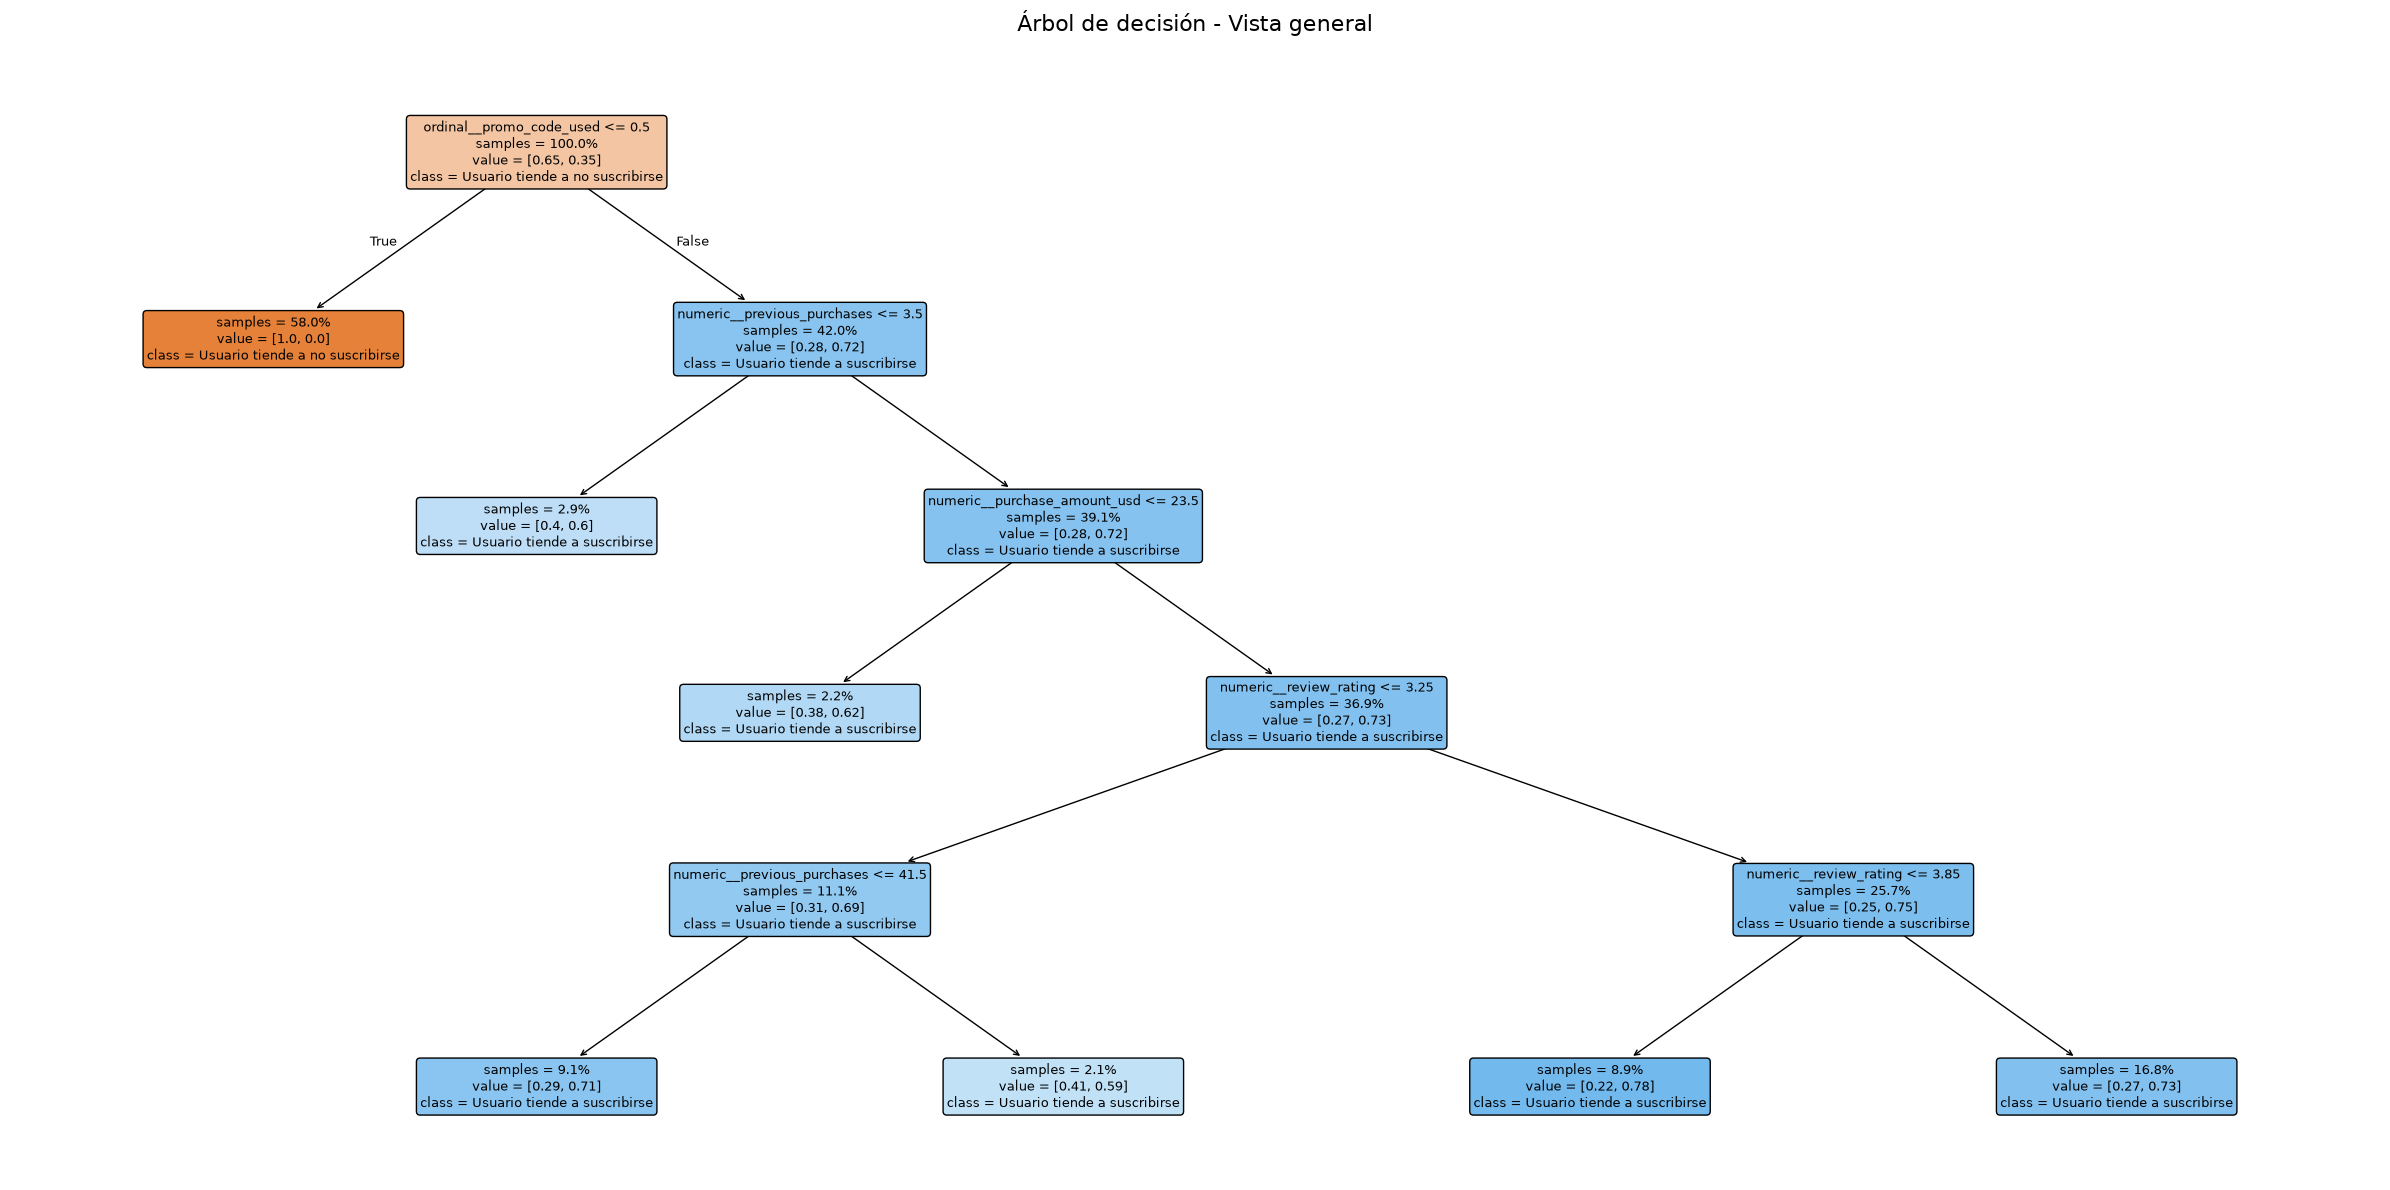

In [143]:
# Crear la figura
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    decision_tree_sin_reduccion,
    max_depth=15,  # Mostrar solo los primeros niveles
    filled=True,
    rounded=True,
    feature_names=nombres_variables,
    class_names=nombre_clases,
    fontsize=9,
    proportion=True,
    precision=2,
    impurity=False,
    ax=ax
)

ax.set_title(
    "Árbol de decisión - Vista general",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.show()

In [144]:
pd.DataFrame({'Columnas preprocesadas':nombres_variables, 'Importancia':decision_tree_sin_reduccion.feature_importances_}).sort_values(by='Importancia', ascending=False).round(10)#['Columnas preprocesadas']

,Columnas preprocesadas,Importancia
3,ordinal__promo_code_used,0.990534
2,numeric__previous_purchases,0.004699
1,numeric__review_rating,0.002980
0,numeric__purchase_amount_usd,0.001786
4,ordinal__frequency_of_purchases,0.000000


#### Elasticnet

In [146]:
pipeline_elasticnet_sin_reduccion = optimizer.search_objects[("ElasticNet", "Sin reducción")].best_estimator_

In [147]:
elasticnet_sin_reduccion = pipeline_elasticnet_sin_reduccion.named_steps['model']

##### Evaluación individual

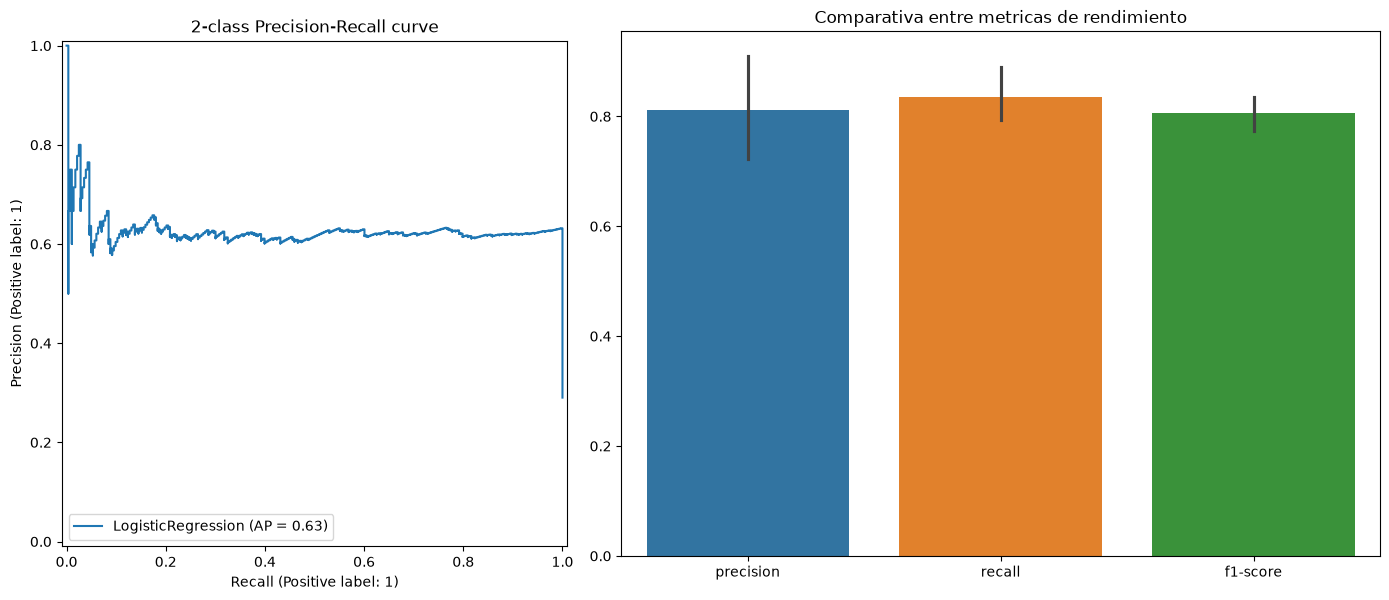

{'y_pred': array([1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,
        0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 0,

In [148]:
eval_model(model=elasticnet_sin_reduccion, is_classification=True, X=X_test, y=y_test)

##### Interpretavilidad

In [149]:
pd.DataFrame({'Columns':preprocessor.get_feature_names_out(), 'Coeficientes':elasticnet_sin_reduccion.coef_[0]}).sort_values(by=['Coeficientes'], ascending=False)

,Columns,Coeficientes
3,ordinal__promo_code_used,3.854165
2,numeric__previous_purchases,-0.002530
0,numeric__purchase_amount_usd,-0.003244
4,ordinal__frequency_of_purchases,-0.066918
1,numeric__review_rating,-0.306874


##### Hipotesis diagnosticas sobre variables asociadas a la suscripción

A partir de los resultados obtenidos en la primera iteración del modelado, se identificaron cinco variables relevantes para la segmentación de los clientes según su propensión a suscribirse: el uso de códigos promocionales, el monto de la compra, la valoración del producto (review_rating) y el número de compras previas, y el monto de compra hecho por el usuario (siendo esta ultima una relación aparentemente no lineal o bajo ciertos segmentos muy concretos, dado que el arbol le asigna una de las importancias mas altas, mientras que ElasticNet un coeficiente nulo).

Durante esta breve instancia de interpretabilidad diagnostica, el objetivo contrastar estas hipótesis mediante el análisis de las tasas de suscripción por grupos, la visualización de sus distribuciones y la comparación de las diferencias observadas. De este modo, se buscará determinar la dirección y magnitud de las asociaciones entre las variables seleccionadas y la suscripción, sin asumir de antemano que estas relaciones son crecientes ni que implican causalidad.




H1. Uso de códigos promocionales: la tasa de suscripción difiere entre los clientes que utilizan códigos promocionales y aquellos que no los utilizan.




Tabla de contingencia bivariada en mapa de calor

In [150]:
tabla_contingencia_promo_c_target = pd.crosstab(df_processed['subscription_status'], df_processed['promo_code_used'], normalize=True)
tabla_contingencia_promo_c_target

promo_code_used,no,yes
subscription_status,,
no,0.57,0.16
yes,0.00,0.27


In [151]:
df_processed[df_processed['promo_code_used'] == 'yes']['subscription_status'].value_counts(normalize=True)

subscription_status
yes    0.627907
no     0.372093
Name: proportion, dtype: float64

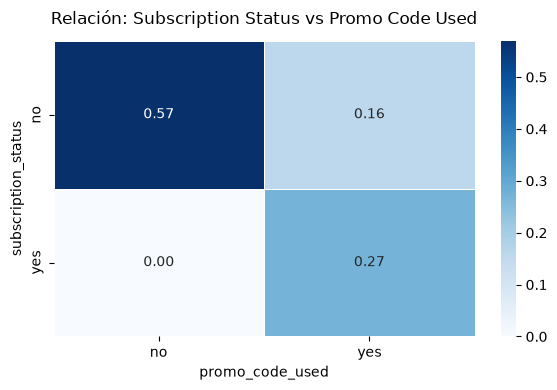

In [152]:
# Definir el tamaño de la figura para que no se vea apretada
plt.figure(figsize=(6, 4))

sns.heatmap(
    data=tabla_contingencia_promo_c_target,
    annot=True,  # Muestra los valores numéricos en las celdas
    fmt='.2f',  # Formato de decimales (usa 'd' si tu tabla tiene conteos enteros)
    cmap='Blues',  # Paleta secuencial, ideal para proporciones/conteos
    linewidths=0.5,  # Líneas de separación entre celdas
    linecolor='white',  # Color de las líneas divisorias
    cbar=True,  # Mantiene la barra de escala lateral
)

# Agregar títulos y etiquetas claras
plt.title(
    'Relación: Subscription Status vs Promo Code Used', fontsize=12, pad=12
)
plt.xlabel('promo_code_used', fontsize=10)
plt.ylabel('subscription_status', fontsize=10)

plt.tight_layout()
plt.show()

Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

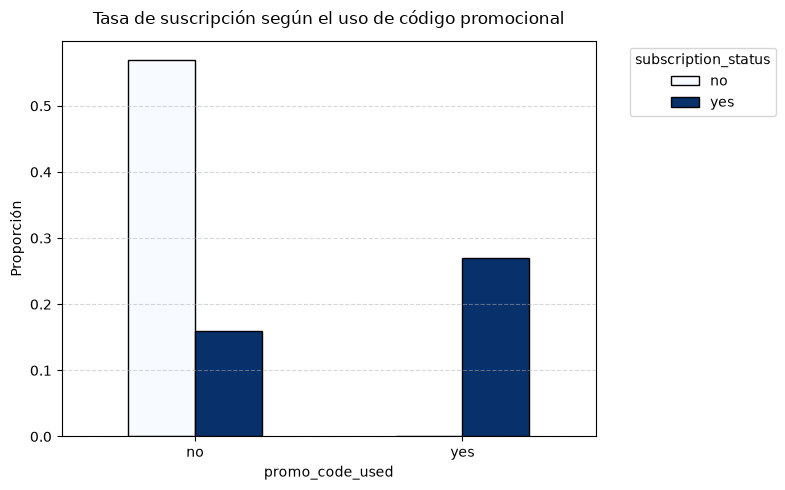

In [154]:
# Generar el gráfico de barras directamente desde la tabla de contingencia
tabla_contingencia_promo_c_target.plot(
    kind='bar',
    figsize=(8, 5),
    colormap='Blues',  # Paleta de colores
    edgecolor='black',  # Borde negro sutil para las barras
)

# Personalizar el gráfico
plt.title(
    'Tasa de suscripción según el uso de código promocional',
    fontsize=12,
    pad=12,
)
plt.xlabel('promo_code_used', fontsize=10)
plt.ylabel('Proporción', fontsize=10)
plt.xticks(rotation=0)  # Mantiene las etiquetas horizontales
plt.legend(title='subscription_status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Prueba de independencia chi-cuadrado bivariada

In [ ]:
chi2_stat, p_value, dof, expected = chi2_contingency(pd.crosstab(df_processed['subscription_status'], df_processed['promo_code_used']))
p_value

np.float64(0.0)

Esta hipotesis claramente es verdadera. En este caso tal como nos muestra la tabla de contingencia, el grafico de barras, y los dos test de hiptesis. Usuarios que reciben el codigo promocional se observa que tienden a subscribirse, en una relación del 62% frente al 37% de las muestras que caen en este segmento.

H2. Numero de compras previas mayores, tienden a estar relacionadas con mayor probabilidad de subscripción

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

<Axes: ylabel='previous_purchases'>

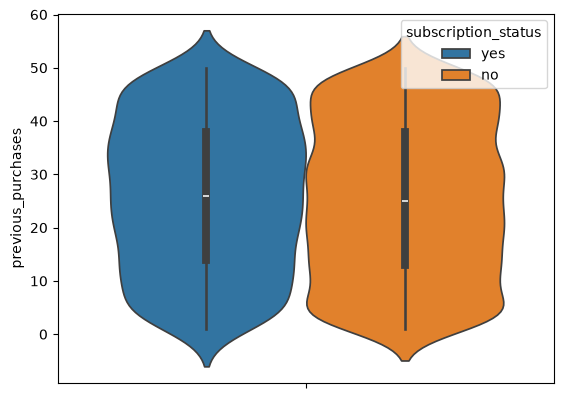

In [155]:
sns.violinplot(df_processed, y='previous_purchases', hue='subscription_status')

Test de Anova

In [156]:
df_processed.groupby(by='subscription_status')['previous_purchases'].mean()

subscription_status
no     25.080436
yes    26.084520
Name: previous_purchases, dtype: float64

In [157]:
# Función auxiliar para calcular la D de Cohen
def calcular_cohens_d(g1, g2):
    n_1, n_2 = len(g1), len(g2)
    media_1, media_2 = np.mean(g1), np.mean(g2)
    var_1, var_2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    # Desviación estándar agrupada (pooled standard deviation)
    pooled_std = np.sqrt(((n_1 - 1) * var_1 + (n_2 - 1) * var_2) / (n_1 + n_2 - 2))
    
    # Si la variabilidad es 0, evitamos división por cero
    if pooled_std == 0:
        return 0.0
        
    return (media_1 - media_2) / pooled_std

In [158]:
# Separar la variable numérica según las categorías de suscripción
compras_no = df_processed[df_processed['subscription_status'] == 'no'][
    'previous_purchases'
]
compras_yes = df_processed[df_processed['subscription_status'] == 'yes'][
    'previous_purchases'
]

In [159]:
f_stat, p_val_anova = stats.f_oneway(compras_no, compras_yes)

print(f"--- ANOVA ---")
print(f"F-statistic: {f_stat}")
print(f"P-value: {p_val_anova}")

--- ANOVA ---
F-statistic: 3.7156225076222866
P-value: 0.05397809617764757


Se observa un p-value cercano a  0.5 por lo que se realizara un analisis del tamańo del efecto.

In [160]:
cohen_d_val = calcular_cohens_d(compras_no, compras_yes)
print(f"D de Cohen: {cohen_d_val:.4f}")

D de Cohen: -0.0695


D de Cohen ($-0.0695$): Un valor absoluto menor a $0.2$ se considera un efecto trivial o insignificante. La diferencia entre las medias de ambos grupos es de apenas una fracción de la desviación estándar (menos del 7%).

Test de Mann-Whitney U

In [161]:
df_processed.groupby('subscription_status')['previous_purchases'].median()

subscription_status
no     25.0
yes    26.0
Name: previous_purchases, dtype: float64

In [164]:
u_stat, p_val_mwu = stats.mannwhitneyu(compras_no, compras_yes, alternative='two-sided')
print(f"P-value Mann-Whitney: {p_val_mwu}")

P-value Mann-Whitney: 0.05252329112817023


Se observa un p-value de 'Mann-Whitney' cercano al 0.05, por lo que se constrastara con un analisis del tamańo del efecto.

In [165]:
# Tamaños de muestra
n1 = len(compras_no)
n2 = len(compras_yes)

# Calcular la correlación biserial de rangos (r_rb)
# Fórmula basada en el estadístico U devuelto por scipy
r_rb = (2 * u_stat) / (n1 * n2) - 1


print(f"Correlación Biserial de Rangos (r): {r_rb:.4f}\n")

Correlación Biserial de Rangos (r): -0.0404



Correlación Biserial de Rangos ($-0.0404$): Al estar tan cerca de $0$, indica que los rangos de los datos de ambos grupos se superponen casi por completo; el ordenamiento de los valores es prácticamente aleatorio entre un grupo y otro.

Se rechaza esta hipotesis, en el caso de la importancia asignada al modelo del arbol en iteraciones donde se le dio mucha profundidad, esta puede ser utilizada en nodos muy profundos bajo vrias condiciones previas, para separar algunos puntos; mientras que en ElasticNet puede deverse a cierta asosiación entre predictoras. El hecho de que el valor $p$ se haya acercado tanto a $0.05$ se debe puramente a que tienes una muestra grande (lo que le da mucha sensibilidad a las pruebas estadísticas para detectar variaciones minúsculas), pero la diferencia real entre los clientes con suscripción y sin suscripción en términos de compras previas es nula. `previous_purchases` se comporta de manera prácticamente idéntica para ambos grupos (`yes` y `no`)

H3. Ratings mas altos, tienden a mayor tasa de subscripción

Gráfico de caja con numero de ratings, separado por subscripción vs no subscripción

<Axes: ylabel='review_rating'>

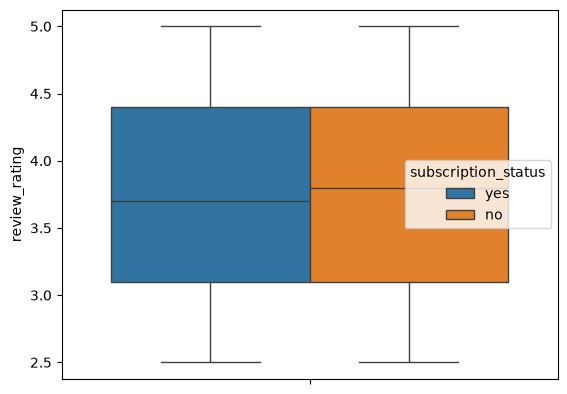

In [166]:
sns.boxplot(df_processed, y='review_rating', hue='subscription_status')

Grafico de barras de la tasa de suscripción por intervalos de rating (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

In [167]:
df_processed['discrete_review_rating'] = pd.qcut(df_processed['review_rating'],q=4, labels=['bajo', 'bajo-medio', 'medio-alto', 'alto'])
df_processed['discrete_review_rating']

0             bajo
1             bajo
2             bajo
3       bajo-medio
4             bajo
           ...    
3895    medio-alto
3896          alto
3897          bajo
3898    medio-alto
3899          bajo
Name: discrete_review_rating, Length: 3900, dtype: category
Categories (4, str): ['bajo' < 'bajo-medio' < 'medio-alto' < 'alto']

<Axes: xlabel='discrete_review_rating'>

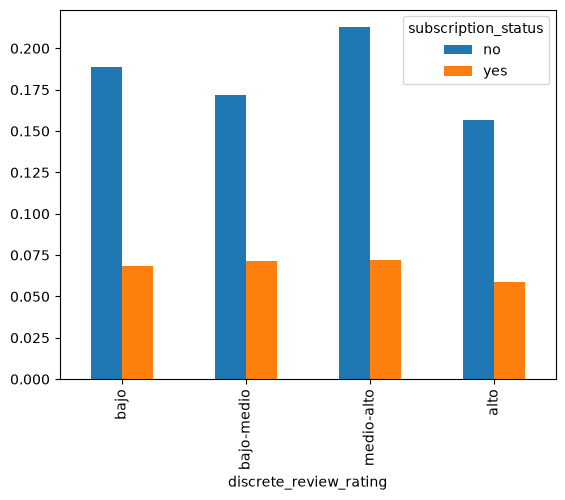

In [168]:
pd.crosstab(df_processed['discrete_review_rating'], df_processed['subscription_status'], normalize=True).plot(
    kind='bar'
)

<Axes: xlabel='subscription_status', ylabel='discrete_review_rating'>

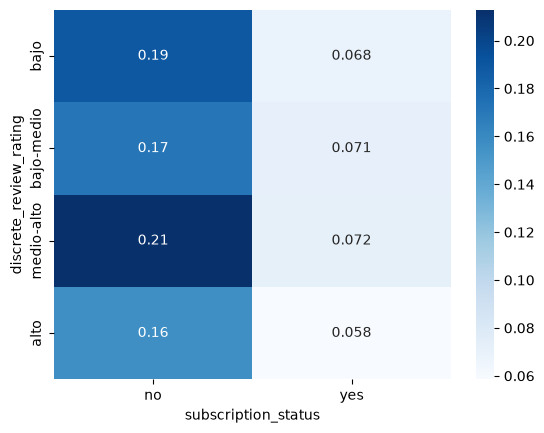

In [169]:
sns.heatmap(pd.crosstab(df_processed['discrete_review_rating'], df_processed['subscription_status'], normalize=True), annot=True, cmap='Blues')

Test de Chi-cuadrado

In [170]:
# 2. Test de Chi-cuadrado
t_contingencia_chi2 = pd.crosstab(df_processed['discrete_review_rating'], df_processed['subscription_status'])
chi2, p_val, dof, expected = stats.chi2_contingency(t_contingencia_chi2)

# 3. V de Cramér (Tamaño del efecto para variables categóricas)
n = t_contingencia_chi2.sum().sum()
min_dim = min(t_contingencia_chi2.shape) - 1
cramer_v = np.sqrt(chi2 / (n * min_dim))

print(f"Chi-cuadrado p-value: {p_val}")
print(f"V de Cramér: {cramer_v:.4f}")

Chi-cuadrado p-value: 0.208952926889266
V de Cramér: 0.0341


Test de Anova

In [171]:
# Separar la variable numérica según las categorías de suscripción
compras_no = df_processed[df_processed['subscription_status'] == 'no'][
    'review_rating'
]
compras_yes = df_processed[df_processed['subscription_status'] == 'yes'][
    'review_rating'
]

In [172]:
# Ejecutar la prueba ANOVA
f_stat, p_value = stats.f_oneway(compras_no, compras_yes)

print(f"P-value: {p_value}")

P-value: 0.690953510741934


In [173]:
df_processed.groupby(by=['subscription_status'])['review_rating'].mean()

subscription_status
no     3.752722
yes    3.742450
Name: review_rating, dtype: float64

Test de Mann-Whitney U

In [174]:
stat, p_val = stats.mannwhitneyu(compras_no, compras_yes)
print(f"P-value Mann-Whitney: {p_val}")

P-value Mann-Whitney: 0.7011474610176017


In [175]:
df_processed.groupby(by=['subscription_status'])['review_rating'].median()

subscription_status
no     3.8
yes    3.7
Name: review_rating, dtype: float64

Se rechaza parcialmente la hipotesis. 

De manera marginal con respecto a la target: El comportamiento de los usuarios respecto al estado de suscripción (yes vs no) es independiente de las calificaciones (review_rating) que otorgan. La tasa de suscripción se mantiene prácticamente constante a lo largo de todos los niveles de satisfacción/calificación.    

De manera multivariable: Modelos de arbol profundo tienden a darle importancia para realizar particiones sobre segmentos muy especificos, y ElasticNet le asigno un coeficiente muy alto (lo que podria indicar cierto sobre ajuste o multicolinealidad con otras variables), por tanto se repetira el proceso de modelado aumentado la penalización.

H4. Usuarios con frecuencia de compras mas consecutivos en el tiempo, tienden a subscribirse mas

In [176]:
tabla_contingencia_review_rating = pd.crosstab(df_processed['frequency_of_purchases'], df_processed['subscription_status'], normalize=True)
tabla_contingencia_review_rating

subscription_status,no,yes
frequency_of_purchases,,
annually,0.105641,0.041026
bi-weekly,0.204103,0.075128
monthly,0.103590,0.038205
quarterly,0.218718,0.075385
weekly,0.097949,0.040256


Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

<Axes: xlabel='frequency_of_purchases'>

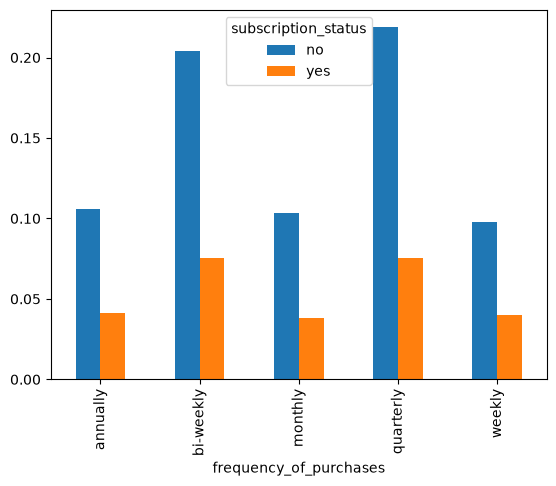

In [177]:
tabla_contingencia_review_rating.plot(kind='bar')

Tabla de contingencia bivariada en mapa de calor

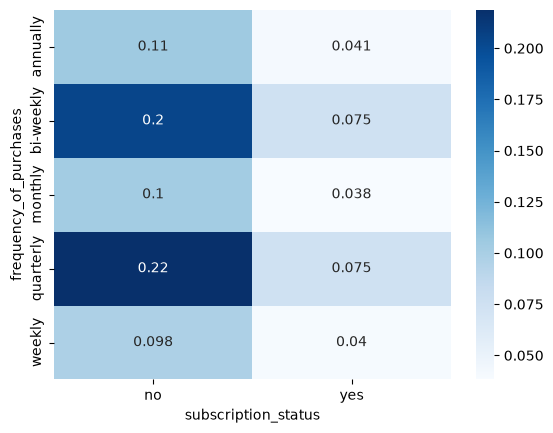

In [178]:
sns.heatmap(tabla_contingencia_review_rating, cmap='Blues', annot=True)
plt.show()

Prueba de independencia chi-cuadrado bivariada

In [179]:
chi2_stat, p_value, dof, expected = chi2_contingency(pd.crosstab(df_processed['frequency_of_purchases'], df_processed['subscription_status']))
p_value

np.float64(0.625527568929042)

Se rechaza la hipotesis de asosiación directa. 
Si observamos las proporciones condicionales en el mapa de calor (o en las barras), la tasa de suscripción (yes) se mantiene notablemente homogénea sin importar la frecuencia de compra:   

- Annually: $\approx 27.1\%$ de suscritos ($0.041 / (0.11 + 0.041)$)   
- Bi-weekly: $\approx 27.2\%$ de suscritos ($0.075 / (0.20 + 0.075)$)  
- Monthly: $\approx 27.5\%$ de suscritos ($0.038 / (0.10 + 0.038)$)   
- Quarterly: $\approx 25.4\%$ de suscritos ($0.075 / (0.22 + 0.075)$)   
- Weekly: $\approx 29.0\%$ de suscritos ($0.040 / (0.098 + 0.040)$)  

Algo que el chi-2 termina de confirmar con un p-value de 0.62, muy por arriba del valor de significancia de 0.05

La frecuencia con la que un cliente realiza compras previas no es un factor determinante para que adopte la suscripción, puede ser util para terminar de subsegmentar, ya segmentos bastantes delimitados.

H5. Montos de compras superiores, tienden a mayor subscripción

> En esta hipotesis en particular, se deberia analizar especificamente el segmento que identifico el arbol, ya que es una partición que tiene sentido para este, y no de manera lineal directa con la target. Recordemos que ElasticNet bajo el coeficiente asignado a 0, y que en configuraciones actuales y menos profunda del arbol, la importancia tambien cayo a 0.

In [180]:
# 1. Filtramos el segmento de interés basado en lo que muestra el árbol
segmento_especifico_h3 = df_processed[
    df_processed['promo_code_used'] == 'yes'
]

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

<Axes: ylabel='purchase_amount_usd'>

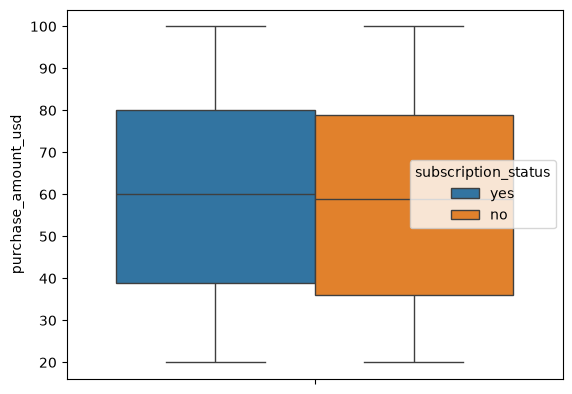

In [181]:
sns.boxplot(segmento_especifico_h3, y='purchase_amount_usd', hue='subscription_status')

Grafico de barras de la tasa de suscripción por intervalos de monto (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

In [182]:
segmento_especifico_h3['discrete_purchase_usd'] = pd.qcut(segmento_especifico_h3['purchase_amount_usd'], q=4, labels=['bajo', 'medio-bajo', 'medio-alto', 'alto'])

<Axes: xlabel='discrete_purchase_usd'>

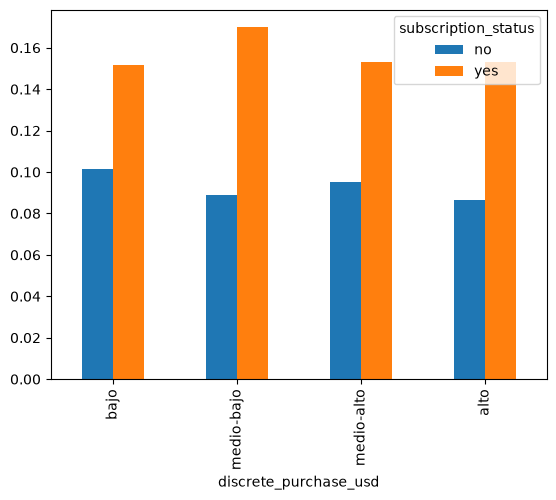

In [183]:
pd.crosstab(segmento_especifico_h3['discrete_purchase_usd'], segmento_especifico_h3['subscription_status'], normalize=True).plot(kind='bar')

Test de Anova

In [184]:
# Separar la variable numérica según las categorías de suscripción
compras_no = segmento_especifico_h3[segmento_especifico_h3['subscription_status'] == 'no'][
    'purchase_amount_usd'
]
compras_yes = segmento_especifico_h3[segmento_especifico_h3['subscription_status'] == 'yes'][
    'purchase_amount_usd'
]

In [185]:
# Ejecutar la prueba ANOVA
f_stat, p_value = stats.f_oneway(compras_no, compras_yes)

print(f"Estadístico F: {f_stat:.4f}")
print(f"P-value: {p_value}")

Estadístico F: 0.2299
P-value: 0.6316602552274833


Test de Mann-Whitney U

In [186]:
stat, p_val = stats.mannwhitneyu(compras_no, compras_yes)
print(f"P-value Mann-Whitney: {p_val}")

P-value Mann-Whitney: 0.6131356469389277


### Guardado del mejor modelo

In [187]:
# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model = '../models/subscription_status_decision_tree_base_model.pkl'
joblib.dump(decision_tree_sin_reduccion, path_best_ml_model)

['../models/subscription_status_decision_tree_base_model.pkl']

---